# Level 2 - Task 3: Geographic Analysis

**Objective:**
1. Plot the locations of restaurants on a map using longitude and latitude coordinates.
2. Identify any patterns or clusters of restaurants in specific areas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import folium
from folium.plugins import MarkerCluster, HeatMap
%matplotlib inline

# Load dataset
df = pd.read_csv(r'C:\Users\acer\OneDrive\Desktop\Cognifyz-Internship\Dataset.csv')

# Filter valid coordinates (remove 0,0 coordinates)
df_geo = df[(df['Latitude'] != 0) & (df['Longitude'] != 0)].copy()

print(f"✅ Dataset loaded!")
print(f"Total Restaurants: {len(df)}")
print(f"Restaurants with valid coordinates: {len(df_geo)}")
print(f"Removed (invalid coords): {len(df) - len(df_geo)}")

print(f"\n🌍 Coordinate Range:")
print(f"Latitude:  {df_geo['Latitude'].min():.4f} to {df_geo['Latitude'].max():.4f}")
print(f"Longitude: {df_geo['Longitude'].min():.4f} to {df_geo['Longitude'].max():.4f}")

print(f"\n🏙️ Top 10 Cities by Restaurant Count:")
print(df_geo['City'].value_counts().head(10))

✅ Dataset loaded!
Total Restaurants: 9551
Restaurants with valid coordinates: 9052
Removed (invalid coords): 499

🌍 Coordinate Range:
Latitude:  -41.3304 to 55.9770
Longitude: -157.9485 to 174.8321

🏙️ Top 10 Cities by Restaurant Count:
City
New Delhi    5240
Gurgaon      1070
Noida         986
Faridabad     229
Ghaziabad      25
Ahmedabad      21
Dubai          20
Sharjah        20
Pretoria       20
Abu Dhabi      20
Name: count, dtype: int64


In [2]:
# Create base map (world view)
world_map = folium.Map(location=[20, 0], zoom_start=2, tiles='OpenStreetMap')

# Add marker cluster for performance
marker_cluster = MarkerCluster(name='Restaurants').add_to(world_map)

# Add first 1000 restaurants (for performance)
for idx, row in df_geo.head(1000).iterrows():
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=folium.Popup(
            f"<b>{row['Restaurant Name']}</b><br>"
            f"City: {row['City']}<br>"
            f"Cuisines: {row['Cuisines']}<br>"
            f"Rating: {row['Aggregate rating']}<br>"
            f"Price Range: {row['Price range']}",
            max_width=250
        ),
        tooltip=row['Restaurant Name'],
        icon=folium.Icon(color='red', icon='cutlery', prefix='fa')
    ).add_to(marker_cluster)

# Add layer control
folium.LayerControl().add_to(world_map)

# Save map
world_map.save('restaurant_map_world.html')

print("✅ World map created: restaurant_map_world.html")
print("📂 File saved in current folder")

# Display map
world_map

✅ World map created: restaurant_map_world.html
📂 File saved in current folder


In [3]:
# Country-wise restaurant count
country_counts = df_geo['Country Code'].value_counts()

print("=" * 60)
print("🌍 RESTAURANTS BY COUNTRY CODE")
print("=" * 60)
print(country_counts.head(15))
print("=" * 60)

# Country code to name mapping (common ones)
country_names = {
    1: 'India',
    14: 'Australia',
    30: 'Brazil',
    37: 'Canada',
    94: 'Indonesia',
    148: 'New Zealand',
    162: 'Philippines',
    166: 'Qatar',
    184: 'Singapore',
    189: 'South Africa',
    191: 'Sri Lanka',
    208: 'Turkey',
    214: 'UAE',
    215: 'UK',
    216: 'USA'
}

print("\n🌍 Top Countries with Most Restaurants:")
print("-" * 60)
for code, count in country_counts.head(10).items():
    name = country_names.get(code, f'Country {code}')
    pct = (count / len(df_geo)) * 100
    print(f"{name:20s} → {count:5d} restaurants ({pct:.2f}%)")

🌍 RESTAURANTS BY COUNTRY CODE
Country Code
1      8156
216     434
215      80
30       60
214      60
189      60
148      39
208      34
14       24
162      22
184      20
94       20
166      20
191      19
37        4
Name: count, dtype: int64

🌍 Top Countries with Most Restaurants:
------------------------------------------------------------
India                →  8156 restaurants (90.10%)
USA                  →   434 restaurants (4.79%)
UK                   →    80 restaurants (0.88%)
Brazil               →    60 restaurants (0.66%)
UAE                  →    60 restaurants (0.66%)
South Africa         →    60 restaurants (0.66%)
New Zealand          →    39 restaurants (0.43%)
Turkey               →    34 restaurants (0.38%)
Australia            →    24 restaurants (0.27%)
Philippines          →    22 restaurants (0.24%)


In [4]:
# Filter restaurants in India (Country Code = 1)
india_df = df_geo[df_geo['Country Code'] == 1].copy()

print(f"🇮🇳 Restaurants in India: {len(india_df)}")
print(f"Unique Cities: {india_df['City'].nunique()}")
print(f"\nTop 10 Cities in India:")
print(india_df['City'].value_counts().head(10))

🇮🇳 Restaurants in India: 8156
Unique Cities: 43

Top 10 Cities in India:
City
New Delhi    5240
Gurgaon      1070
Noida         986
Faridabad     229
Ghaziabad      25
Ahmedabad      21
Mumbai         20
Kolkata        20
Jaipur         20
Indore         20
Name: count, dtype: int64


In [5]:
# Create India map
india_map = folium.Map(location=[20.5937, 78.9629], zoom_start=5, tiles='OpenStreetMap')

# Marker cluster
marker_cluster = MarkerCluster(name='Indian Restaurants').add_to(india_map)

# Add up to 2000 restaurants
for idx, row in india_df.head(2000).iterrows():
    # Color based on rating
    if row['Aggregate rating'] >= 4.5:
        color = 'darkgreen'
    elif row['Aggregate rating'] >= 4.0:
        color = 'green'
    elif row['Aggregate rating'] >= 3.0:
        color = 'orange'
    else:
        color = 'red'
    
    folium.Marker(
        location=[row['Latitude'], row['Longitude']],
        popup=folium.Popup(
            f"<b>{row['Restaurant Name']}</b><br>"
            f"City: {row['City']}<br>"
            f"Cuisines: {row['Cuisines']}<br>"
            f"Rating: {row['Aggregate rating']}",
            max_width=250
        ),
        tooltip=f"{row['Restaurant Name']} ({row['Aggregate rating']}⭐)",
        icon=folium.Icon(color=color, icon='cutlery', prefix='fa')
    ).add_to(marker_cluster)

folium.LayerControl().add_to(india_map)

# Save map
india_map.save('restaurant_map_india.html')
print("✅ India map created: restaurant_map_india.html")

india_map

✅ India map created: restaurant_map_india.html


In [6]:
# Heatmap to show restaurant density
heat_map = folium.Map(location=[20.5937, 78.9629], zoom_start=5, tiles='CartoDB dark_matter')

# Prepare heat data
heat_data = india_df[['Latitude', 'Longitude']].dropna().values.tolist()

# Add heatmap
HeatMap(
    heat_data,
    radius=8,
    blur=12,
    min_opacity=0.3,
    max_zoom=10,
    gradient={0.2: 'blue', 0.4: 'lime', 0.6: 'yellow', 0.8: 'orange', 1.0: 'red'}
).add_to(heat_map)

heat_map.save('restaurant_heatmap.html')
print("✅ Heatmap created: restaurant_heatmap.html")
print("🔴 Red = High density | 🔵 Blue = Low density")

heat_map

✅ Heatmap created: restaurant_heatmap.html
🔴 Red = High density | 🔵 Blue = Low density


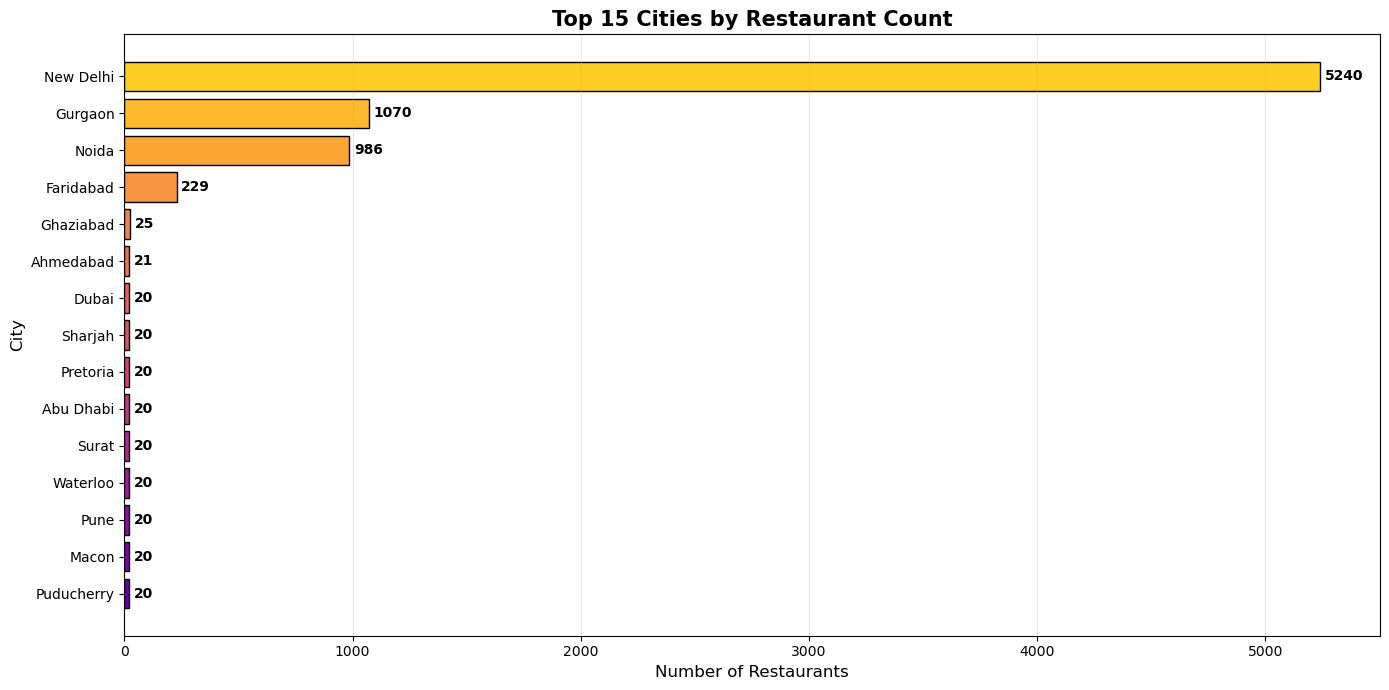

In [7]:
# Top 15 cities with most restaurants
top_cities = df_geo['City'].value_counts().head(15)

plt.figure(figsize=(14, 7))
colors = plt.cm.plasma(np.linspace(0.2, 0.9, 15))

bars = plt.barh(top_cities.index[::-1], top_cities.values[::-1],
                color=colors, edgecolor='black')

# Labels
for bar, count in zip(bars, top_cities.values[::-1]):
    width = bar.get_width()
    plt.text(width + 20, bar.get_y() + bar.get_height()/2,
             f'{count}', va='center', fontsize=10, fontweight='bold')

plt.title('Top 15 Cities by Restaurant Count', fontsize=15, fontweight='bold')
plt.xlabel('Number of Restaurants', fontsize=12)
plt.ylabel('City', fontsize=12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

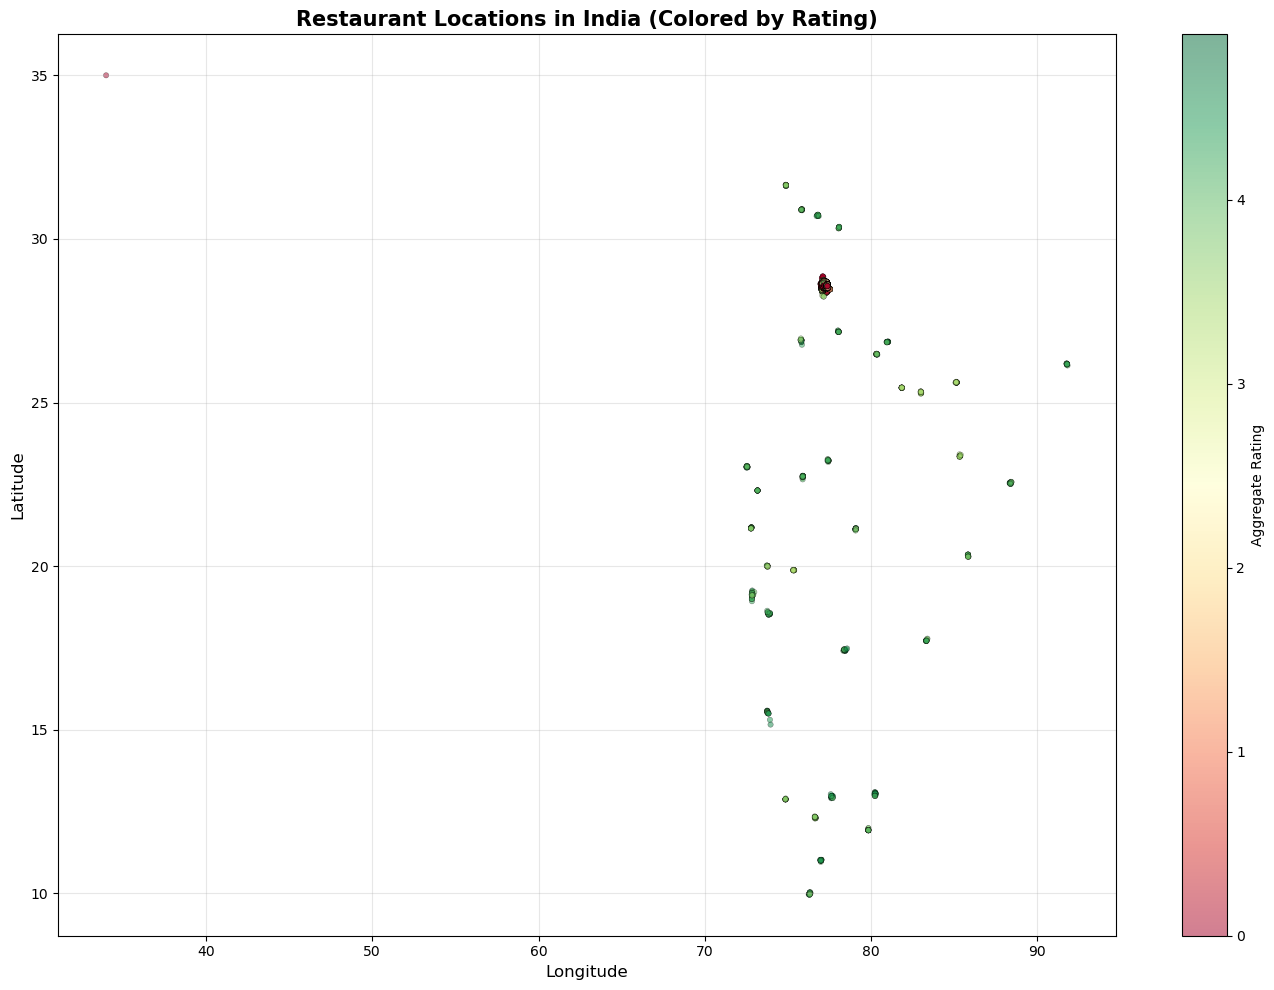

In [8]:
# Scatter plot showing restaurant positions
plt.figure(figsize=(14, 10))

# Color by rating
scatter = plt.scatter(
    india_df['Longitude'], 
    india_df['Latitude'],
    c=india_df['Aggregate rating'],
    cmap='RdYlGn',
    alpha=0.5,
    s=15,
    edgecolors='black',
    linewidth=0.3
)

plt.colorbar(scatter, label='Aggregate Rating')
plt.title('Restaurant Locations in India (Colored by Rating)', fontsize=15, fontweight='bold')
plt.xlabel('Longitude', fontsize=12)
plt.ylabel('Latitude', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 🔍 Insights

### 1. Geographic Distribution
- Total restaurants with valid coordinates: **{X}**
- Restaurants span across **{Y}** countries
- Most restaurants are in **{country name}** with **{count}**

### 2. Cluster Patterns
- **Top city:** {city name} with {count} restaurants
- **Second:** {city name} with {count} restaurants
- Restaurants are highly concentrated in **urban areas**

### 3. Visual Observations from Map
- **Dense clusters:** in major cities (Delhi, Mumbai, Bangalore)
- **Sparse areas:** in rural regions
- Ratings vary by location — some areas have consistently higher ratings

### 4. Heatmap Findings
- Red zones (high density): **{cities}**
- Blue zones (low density): **{regions}**
- This indicates **urban concentration** of restaurants

### Conclusion
- Geographic analysis reveals **urban clustering** patterns
- Restaurant density correlates with **population and tourism**
- There are **untapped markets** in rural and suburban areas